In [1]:
from pathlib import Path
import warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import STL
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

warnings.filterwarnings("ignore")

# --- modelo ---
ORDEN = (1, 0, 1)          # ARMA(1,1) sobre spread en niveles
TREND = "c"                # con constante en la serie mensual en niveles (pbs)

# --- datos ---
HOJA = "Diarias"
FECHA_INICIO = "2004-01-01"
FECHA_FIN = "2026-08-31"   # excluye septiembre de 2026, que está incompleto
S = 12                     # periodos por año (estacionalidad mensual)

# --- pronóstico y salidas ---
H = 10                     # meses
PUNTO = "media"             # pronóstico en niveles (pbs), sin transformación logarítmica
VENTANA_GRAFICO = 300      # muestra completa desde 2004 y el horizonte hasta 2027
LAGS_LB = [6, 12, 18, 24] # rezagos del Ljung-Box
LAGS_ARCH = [1, 3, 6]     # rezagos del ARCH-LM
AUTORES = "Felipe Ramirez Beltra, Nicolas Gordillo Luna, Julian Mauricio Molina Perez"

# --- rutas ---
BASE_DIR = next((r for r in (Path.cwd(), *Path.cwd().parents)
                 if (r / "base de datos" / "Datos_EMBI.xlsx").is_file()), None)
if BASE_DIR is None:
    raise FileNotFoundError("No se encontró base de datos/Datos_EMBI.xlsx en la carpeta del proyecto ni en sus carpetas superiores.")
ARCHIVO = BASE_DIR / "base de datos" / "Datos_EMBI.xlsx"
SALIDA = BASE_DIR / "code" / "resultados_embi"
SALIDA.mkdir(parents=True, exist_ok=True)

# --- estilo gráfico claro (figuras y póster) ---
plt.style.use("default")
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
C_AZUL, C_VERDE, C_ROJO = "#1F4E78", "#2E7D32", "#C0392B"
C_IC95, C_IC90 = "#F8BBD0", "#EC407A"

R = {}                     # resultados de cada etapa; el póster solo lee este diccionario


## 1. Datos: promedios mensuales, enero de 2004 a agosto de 2026

In [10]:
R = {}   # diccionario de resultados

def cargar_serie(archivo, hoja):
    """Lee fecha y valor (dos primeras columnas) y devuelve la serie indexada por fecha; omite filas inválidas."""
    raw = pd.read_excel(archivo, sheet_name=hoja, header=1)
    col_fecha, col_valor = raw.columns[:2]
    fecha = pd.to_datetime(raw[col_fecha], errors="coerce")
    valor = pd.to_numeric(raw[col_valor], errors="coerce")
    validas = fecha.notna() & valor.notna()
    if not validas.any():
        raise ValueError("No se encontraron filas con fecha y spread válidos.")
    if not validas.all():
        print(f"Filas omitidas por fecha o spread inválido/vacío: {(~validas).sum()}")
    return pd.Series(valor[validas].to_numpy(), index=pd.DatetimeIndex(fecha[validas]), name="spread").sort_index()

def a_mensual(serie, desde=FECHA_INICIO, hasta=FECHA_FIN):
    """Promedia las observaciones diarias de cada mes, dentro del intervalo indicado."""
    serie = serie.loc[(serie.index >= pd.Timestamp(desde)) & (serie.index <= pd.Timestamp(hasta))]
    if serie.empty:
        raise ValueError(f"No hay observaciones válidas entre {desde} y {hasta}.")
    mensual = serie.resample("MS").mean()
    esperados = pd.date_range(pd.Timestamp(desde).to_period("M").to_timestamp(),
                              pd.Timestamp(hasta).to_period("M").to_timestamp(), freq="MS")
    faltantes = esperados.difference(mensual.dropna().index)
    if len(faltantes):
        raise ValueError(f"Faltan observaciones para {len(faltantes)} mes(es): {faltantes.strftime('%m/%Y').tolist()}")
    return mensual.reindex(esperados).rename("spread")

diaria = cargar_serie(ARCHIVO, HOJA)
y = a_mensual(diaria)   # promedio mensual del spread (pbs), 01/2004–08/2026
if (y <= 0).any():
    raise ValueError("El logaritmo natural requiere promedios mensuales positivos.")
ly = np.log(y)          # referencia exploratoria; el modelo ARMA se estima sobre y en niveles

etq_agr = "promedio mensual de observaciones diarias"
R.update(n=len(y), ini=f"{y.index[0]:%m/%Y}", fin=f"{y.index[-1]:%m/%Y}", ultimo=float(y.iloc[-1]), agr=etq_agr)
print(f"Datos originales: {diaria.index.min():%d/%m/%Y} a {diaria.index.max():%d/%m/%Y} ({len(diaria)} filas)")
print(f"Promedios mensuales entre {FECHA_INICIO} y {FECHA_FIN}: {len(y)} obs., {y.index[0]:%m/%Y} a {y.index[-1]:%m/%Y}")
print(y.head(3))

Datos originales: 02/01/1998 a 03/09/2026 (7480 filas)
Promedios mensuales entre 2004-01-01 y 2026-08-31: 272 obs., 01/2004 a 08/2026
2004-01-01    389.000000
2004-02-01    433.700000
2004-03-01    402.304348
Freq: MS, Name: spread, dtype: float64


## 2. Transformación y varianza

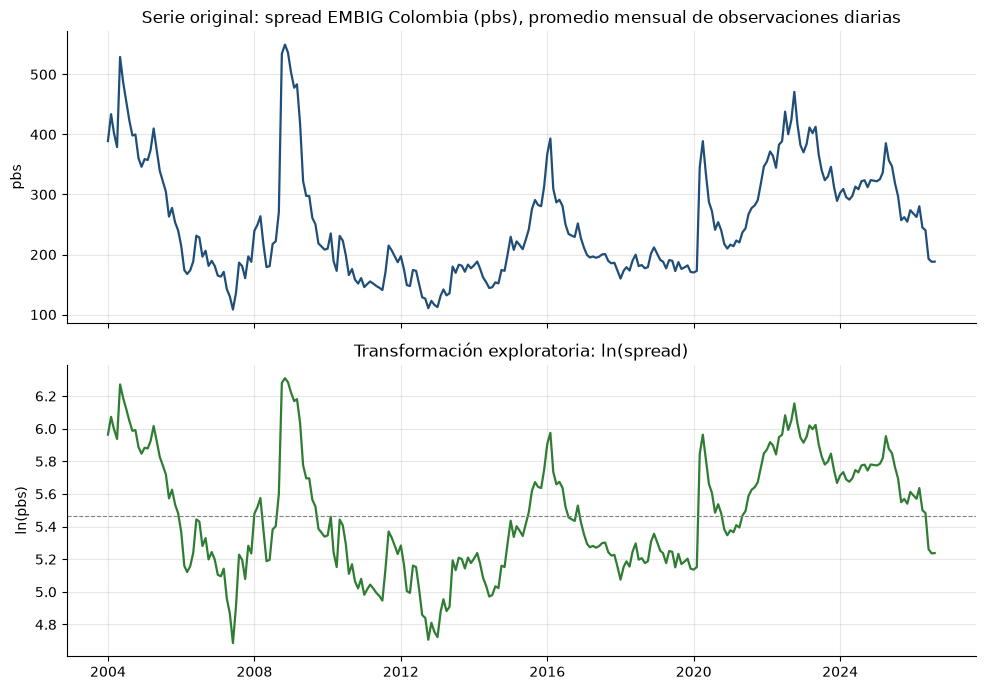

--- Varianza del spread mensual en niveles ---
Serie mensual: promedio mensual de observaciones diarias
Nivel  var1=11250.2243 var2=5646.9104 Levene p=0.2717 | ARCH(1) p=0.6539 ARCH(4) p=0.9783


In [11]:
def grafico_serie(y, ly, ruta, etq):
    fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    ax[0].plot(y.index, y, color=C_AZUL, lw=1.6)
    ax[0].set_title(f"Serie original: spread EMBIG Colombia (pbs), {etq}")
    ax[0].set_ylabel("pbs")
    ax[1].plot(ly.index, ly, color=C_VERDE, lw=1.6)
    ax[1].axhline(ly.mean(), color="gray", lw=.8, ls="--")
    ax[1].set_title("Transformación exploratoria: ln(spread)")
    ax[1].set_ylabel("ln(pbs)")
    plt.tight_layout(); fig.savefig(ruta, dpi=150); plt.show()

def tabla_varianza(series, etq):
    """Resume la varianza del spread en niveles y las pruebas de heterocedasticidad."""
    def arch_ar1(s, lags):
        s = np.asarray(s)
        return het_arch(sm.OLS(s[1:], sm.add_constant(s[:-1])).fit().resid, nlags=lags)[1]
    print(f"Serie mensual: {etq}")
    for nombre, s in series.items():
        s = s.reset_index(drop=True); h = len(s) // 2
        print(f"{nombre:6s} var1={s[:h].var():.4f} var2={s[h:].var():.4f} "
              f"Levene p={stats.levene(s[:h], s[h:]).pvalue:.4f} | "
              f"ARCH(1) p={arch_ar1(s,1):.4f} ARCH(4) p={arch_ar1(s,4):.4f}")

grafico_serie(y, ly, SALIDA / "fig1_transformacion.png", etq_agr)
print("--- Varianza del spread mensual en niveles ---")
tabla_varianza({"Nivel": y}, etq_agr)

## 3. Etapa 1 — Identificación del spread en niveles

=== ETAPA 1: IDENTIFICACIÓN (niveles y ln exploratorio) ===
ADF  reg=c  est=-3.585 p=0.0060 rezagos=1 crit5%=-2.872
KPSS reg=c  est=0.496 p=0.0426 crit5%=0.463
ADF  reg=ct est=-3.655 p=0.0255 rezagos=1 crit5%=-3.427
KPSS reg=ct est=0.410 p=0.0100 crit5%=0.146


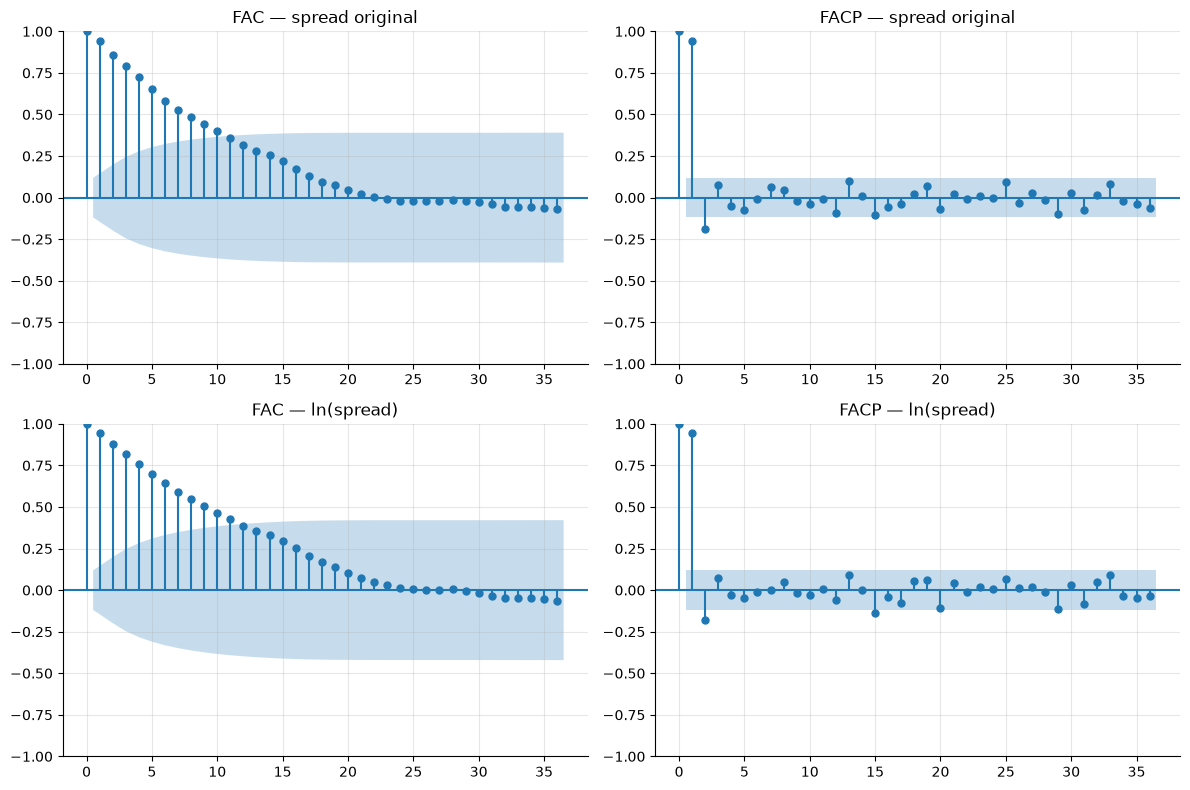

In [12]:
def prueba_adf(s, reg):
    r = adfuller(s, regression=reg, autolag="AIC")
    print(f"ADF  reg={reg:2s} est={r[0]:.3f} p={r[1]:.4f} rezagos={r[2]} crit5%={r[4]['5%']:.3f}")
    return r[1]

def prueba_kpss(s, reg):
    r = kpss(s, regression=reg, nlags=int(4 * (len(s) / 100) ** 0.25))
    print(f"KPSS reg={reg:2s} est={r[0]:.3f} p={r[1]:.4f} crit5%={r[3]['5%']}")
    return r[1]

def grafico_fac_facp(y, ly, ruta, lags=36):
    fig, ax = plt.subplots(2, 2, figsize=(12, 8))
    for fila, (serie, nombre) in enumerate([(y, "spread original"), (ly, "ln(spread)")]):
        plot_acf(serie, lags=lags, ax=ax[fila, 0], title=f"FAC — {nombre}")
        plot_pacf(serie, lags=lags, ax=ax[fila, 1], method="ywm", title=f"FACP — {nombre}")
    plt.tight_layout(); fig.savefig(ruta, dpi=150); plt.show()

print("=== ETAPA 1: IDENTIFICACIÓN (niveles y ln exploratorio) ===")
adf_y = prueba_adf(y, "c"); kpss_y = prueba_kpss(y, "c")
adf_ct_y = prueba_adf(y, "ct"); kpss_ct_y = prueba_kpss(y, "ct")
grafico_fac_facp(y, ly, SALIDA / "fig2_FAC_FACP.png")
R["ident"] = dict(adf_y=adf_y, kpss_y=kpss_y, adf_ct_y=adf_ct_y, kpss_ct_y=kpss_ct_y)

In [5]:
print("=== COMPARACIÓN DE MODELOS: AIC Y BIC ===")
print("Criterios de información (no pruebas de hipótesis); todos los modelos usan el spread mensual en niveles, la misma muestra y constante.")

ajustes_comparables = {
    "AR(1)": ARIMA(y, order=(1, 0, 0), trend=TREND).fit(),
    "AR(2)": ARIMA(y, order=(2, 0, 0), trend=TREND).fit(),
    "MA(1)": ARIMA(y, order=(0, 0, 1), trend=TREND).fit(),
    "ARMA(1,1)": ARIMA(y, order=(1, 0, 1), trend=TREND).fit(),
}

tabla_aic_bic = pd.DataFrame(
    [{"Modelo": nombre, "AIC": ajuste.aic, "BIC": ajuste.bic}
     for nombre, ajuste in ajustes_comparables.items()]
)
tabla_aic_bic["ΔAIC"] = tabla_aic_bic["AIC"] - tabla_aic_bic["AIC"].min()
tabla_aic_bic["ΔBIC"] = tabla_aic_bic["BIC"] - tabla_aic_bic["BIC"].min()
tabla_aic_bic = tabla_aic_bic.sort_values(["BIC", "AIC"]).reset_index(drop=True)
R["comparacion_aic_bic"] = tabla_aic_bic

display(tabla_aic_bic.round(2))
print(f"Preferido por AIC: {tabla_aic_bic.loc[tabla_aic_bic['AIC'].idxmin(), 'Modelo']}")
print(f"Preferido por BIC: {tabla_aic_bic.loc[tabla_aic_bic['BIC'].idxmin(), 'Modelo']}")

=== COMPARACIÓN DE MODELOS: AIC Y BIC ===
Criterios de información (no pruebas de hipótesis); todos los modelos usan el spread mensual en niveles, la misma muestra y constante.


,Modelo,AIC,BIC,ΔAIC,ΔBIC
0,"ARMA(1,1)",2639.84,2654.26,0.00,0.00
1,AR(2),2641.09,2655.51,1.25,1.25
2,AR(1),2648.02,2658.84,8.18,4.58
3,MA(1),2959.86,2970.68,320.02,316.41


Preferido por AIC: ARMA(1,1)
Preferido por BIC: ARMA(1,1)


## 4. Etapa 2 — Estimación del ARMA(1,1)

In [14]:
def ajustar_arma(serie):
    """Ajusta un ARMA(1,1) con constante por máxima verosimilitud."""
    m = ARIMA(serie, order=ORDEN, trend=TREND).fit()
    phi, theta, mu = m.params["ar.L1"], m.params["ma.L1"], m.params["const"]
    ic_phi = m.conf_int().loc["ar.L1"].to_numpy()
    ic_theta = m.conf_int().loc["ma.L1"].to_numpy()
    info = dict(phi=phi, theta=theta, se_phi=m.bse["ar.L1"], p_phi=m.pvalues["ar.L1"],
                ic_phi=ic_phi, ic_incluye_1=bool(ic_phi[0] <= 1 <= ic_phi[1]),
                phi_estacionario=bool(abs(phi) < 1), se_theta=m.bse["ma.L1"],
                p_theta=m.pvalues["ma.L1"], ic_theta=ic_theta,
                theta_invertible=bool(abs(theta) < 1), mu=mu, c=(1 - phi) * mu,
                se_mu=m.bse["const"], p_mu=m.pvalues["const"], sigma2=m.params["sigma2"],
                nivel_lp=float(mu), aic=m.aic, bic=m.bic)
    return m, info

print("=== ETAPA 2: ESTIMACIÓN ARMA(1,1) ===")
modelo, M = ajustar_arma(y)
print(modelo.summary().tables[1])
print(f"AR phi={M['phi']:.3f} (EE {M['se_phi']:.3f}, p={M['p_phi']:.3g}, IC95%=[{M['ic_phi'][0]:.3f}, {M['ic_phi'][1]:.3f}])")
print(f"MA theta={M['theta']:.3f} (EE {M['se_theta']:.3f}, p={M['p_theta']:.3g}, IC95%=[{M['ic_theta'][0]:.3f}, {M['ic_theta'][1]:.3f}])")
print(f"Estacionariedad AR: {'sí' if M['phi_estacionario'] else 'no'} | invertibilidad MA: {'sí' if M['theta_invertible'] else 'no'}")
print(f"Media y nivel de largo plazo = {M['mu']:.2f} (SE {M['se_mu']:.2f}) pbs")
print(f"AIC={M['aic']:.2f} | BIC={M['bic']:.2f} | sigma2={M['sigma2']:.4f}")
R["modelo"] = M


=== ETAPA 2: ESTIMACIÓN ARMA(1,1) ===
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        251.5381     35.832      7.020      0.000     181.308     321.768
ar.L1          0.9206      0.027     34.098      0.000       0.868       0.973
ma.L1          0.2194      0.066      3.336      0.001       0.091       0.348
sigma2       924.8300     33.307     27.767      0.000     859.550     990.110
AR phi=0.921 (EE 0.027, p=7.95e-255, IC95%=[0.868, 0.973])
MA theta=0.219 (EE 0.066, p=0.000849, IC95%=[0.091, 0.348])
Estacionariedad AR: sí | invertibilidad MA: sí
Media y nivel de largo plazo = 251.54 (SE 35.83) pbs
AIC=2639.84 | BIC=2654.26 | sigma2=924.8300


## 5. Etapa 3 — Diagnóstico de residuos

=== ETAPA 3: DIAGNÓSTICO ===
Ljung-Box p [6, 12, 18, 24]: [0.366, 0.51, 0.442, 0.5]
ARCH-LM p [1, 3, 6]: [0.699, 0.99, 0.995]
Jarque-Bera p: 0.00e+00 | asimetría=3.23 curtosis=23.71


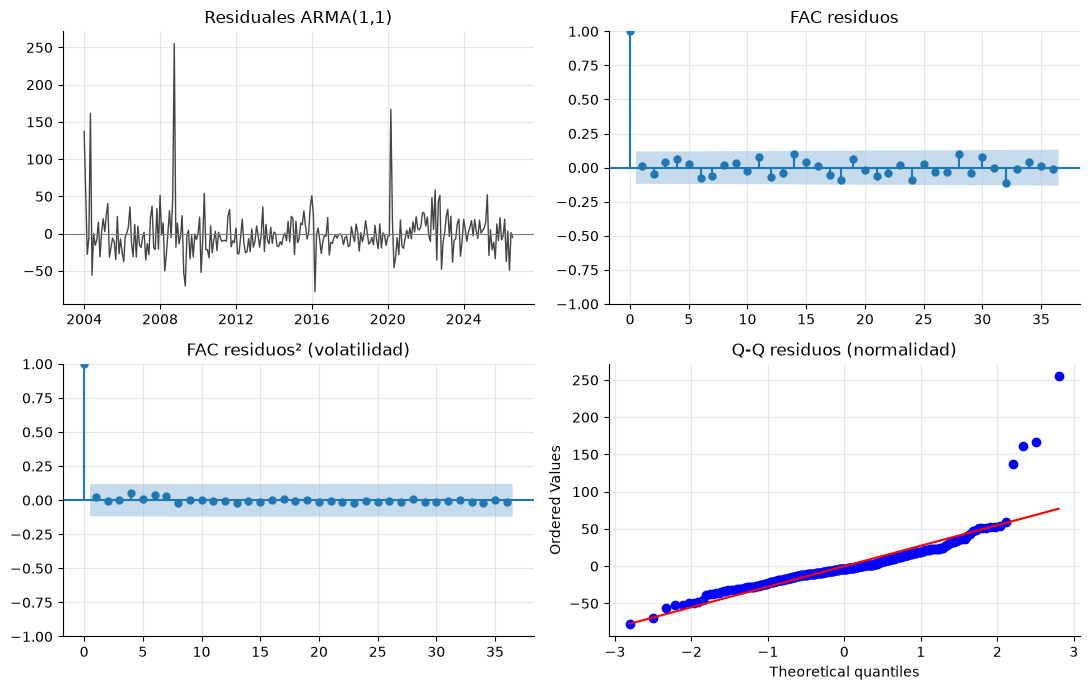

In [15]:
def diagnosticar(m):
    """Pruebas sobre los residuos: Ljung-Box, ARCH-LM, Jarque-Bera."""
    res = np.asarray(m.resid)
    p, _, q = m.model.order
    lb = acorr_ljungbox(res, lags=LAGS_LB, model_df=p + q)["lb_pvalue"].to_numpy()
    arch = np.array([het_arch(res, nlags=k)[1] for k in LAGS_ARCH])
    return dict(lb_p=lb, arch_p=arch, jb_p=stats.jarque_bera(res)[1],
                asim=stats.skew(res), curt=stats.kurtosis(res, fisher=False))

def grafico_residuos(m, ruta, lags=36):
    """Residuales, FAC, FAC de residuos² (volatilidad) y Q-Q (normalidad)."""
    res = pd.Series(np.asarray(m.resid), index=y.index)
    fig, ax = plt.subplots(2, 2, figsize=(11, 7))
    ax[0, 0].plot(res, color="#444", lw=1); ax[0, 0].axhline(0, color="gray", lw=.8); ax[0, 0].set_title("Residuales ARMA(1,1)")
    plot_acf(res, lags=lags, ax=ax[0, 1], title="FAC residuos")
    plot_acf(res ** 2, lags=lags, ax=ax[1, 0], title="FAC residuos² (volatilidad)")
    stats.probplot(res, dist="norm", plot=ax[1, 1]); ax[1, 1].set_title("Q-Q residuos (normalidad)")
    plt.tight_layout(); fig.savefig(ruta, dpi=150); plt.show()

print("=== ETAPA 3: DIAGNÓSTICO ===")
D = diagnosticar(modelo)
print(f"Ljung-Box p {LAGS_LB}:", D["lb_p"].round(3).tolist())
print(f"ARCH-LM p {LAGS_ARCH}:", D["arch_p"].round(3).tolist())
print(f"Jarque-Bera p: {D['jb_p']:.2e} | asimetría={D['asim']:.2f} curtosis={D['curt']:.2f}")
grafico_residuos(modelo, SALIDA / "fig3_residuos.png")
R["diag"] = D


## 6. Etapa 4 — Pronóstico (IC 95% y 90%, en pbs)

=== ETAPA 4: PRONÓSTICO ===
  Fecha  Mediana  Media  IC95_inf  IC95_sup  IC90_inf  IC90_sup
09/2026    192.1  192.1     132.5     251.7     142.1     242.1
10/2026    196.8  196.8     106.4     287.2     121.0     272.7
11/2026    201.2  201.2      91.3     311.1     108.9     293.4
12/2026    205.2  205.2      81.1     329.3     101.0     309.3
01/2027    208.9  208.9      73.9     343.8      95.6     322.1
02/2027    212.3  212.3      68.8     355.7      91.8     332.7
03/2027    215.4  215.4      65.0     365.7      89.2     341.6
04/2027    218.2  218.2      62.3     374.2      87.4     349.1
05/2027    220.9  220.9      60.4     381.4      86.2     355.6
06/2027    223.3  223.3      59.0     387.6      85.4     361.2
Último dato (08/2026): 188 pbs | nivel de largo plazo: 252 pbs
Pronósticos e intervalos calculados directamente en niveles (pbs), sin transformación logarítmica.


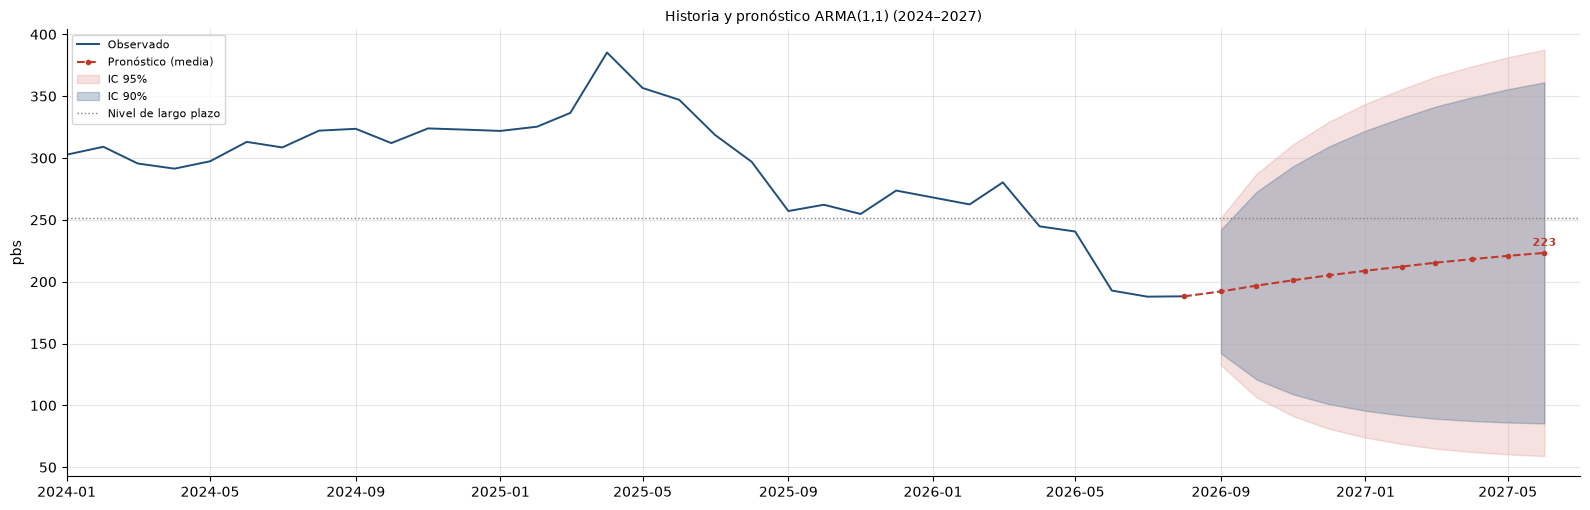

In [16]:
def pronosticar(modelo, fechas, h=H, punto="media"):
    """Pronostica los promedios mensuales del spread en niveles (pbs)."""
    fc = modelo.get_forecast(h)
    pronostico = fc.predicted_mean.values
    fut = [fechas[-1] + pd.DateOffset(months=i + 1) for i in range(h)]
    return dict(fc=fc, fut=fut, mediana=pronostico, media=pronostico, etq=punto,
                punto=pronostico, ic95=fc.conf_int(alpha=0.05).values,
                ic90=fc.conf_int(alpha=0.10).values)

def panel_pronostico(ax, y, P, a95, a90, color, titulo, ref95=None, nivel_lp=None):
    fut, punto = P["fut"], P["punto"]
    ax.plot(y.index[-VENTANA_GRAFICO:], y[-VENTANA_GRAFICO:], color=C_AZUL, lw=1.4, label="Observado")
    ax.plot([y.index[-1], *fut], [y.iloc[-1], *punto], "--o", ms=3, color=color, label=f"Pronóstico ({P['etq']})")
    ax.fill_between(fut, a95[:, 0], a95[:, 1], color=C_ROJO, alpha=.15, label="IC 95%")
    ax.fill_between(fut, a90[:, 0], a90[:, 1], color=C_AZUL, alpha=.25, label="IC 90%")
    if ref95 is not None:
        ax.plot(fut, ref95[:, 0], ":", color="gray", lw=1.3, label="IC 95% original"); ax.plot(fut, ref95[:, 1], ":", color="gray", lw=1.3)
    if nivel_lp is not None:
        ax.axhline(nivel_lp, color="gray", ls=":", lw=1, label="Nivel de largo plazo")
    ax.annotate(f"{punto[-1]:.0f}", xy=(fut[-1], punto[-1]), xytext=(0, 5), textcoords="offset points",
                ha="center", color=color, fontsize=8, fontweight="bold", zorder=10)
    ax.set_title(titulo, fontsize=10); ax.set_ylabel("pbs"); ax.legend(fontsize=8)

print("=== ETAPA 4: PRONÓSTICO ===")
P = pronosticar(modelo, y.index, punto=PUNTO)
pron = pd.DataFrame({"Fecha": [f"{f:%m/%Y}" for f in P["fut"]], "Mediana": P["mediana"], "Media": P["media"],
                     "IC95_inf": P["ic95"][:, 0], "IC95_sup": P["ic95"][:, 1],
                     "IC90_inf": P["ic90"][:, 0], "IC90_sup": P["ic90"][:, 1]})
print(pron.round(1).to_string(index=False))
print(f"Último dato ({y.index[-1]:%m/%Y}): {y.iloc[-1]:.0f} pbs | nivel de largo plazo: {M['nivel_lp']:.0f} pbs")
print("Pronósticos e intervalos calculados directamente en niveles (pbs), sin transformación logarítmica.")
fig, ax = plt.subplots(figsize=(16, 5.2))
inicio_grafico = pd.Timestamp("2024-01-01")
panel_pronostico(ax, y, P, P["ic95"], P["ic90"], C_ROJO, "Historia y pronóstico ARMA(1,1) (2024–2027)", nivel_lp=M["nivel_lp"])
datos_visibles = y.loc[inicio_grafico:]
y_min = min(float(datos_visibles.min()), float(P["ic95"][:, 0].min()))
y_max = max(float(datos_visibles.max()), float(P["ic95"][:, 1].max()))
margen = 0.05 * (y_max - y_min)
ax.set_xlim(inicio_grafico, P["fut"][-1] + pd.DateOffset(months=1))
ax.set_ylim(y_min - margen, y_max + margen)
plt.tight_layout(); fig.savefig(SALIDA / "fig4_pronostico.png", dpi=200); plt.show()
R["pron"] = P


## 7. Etapa 6 — Póster (PDF, paleta clara)

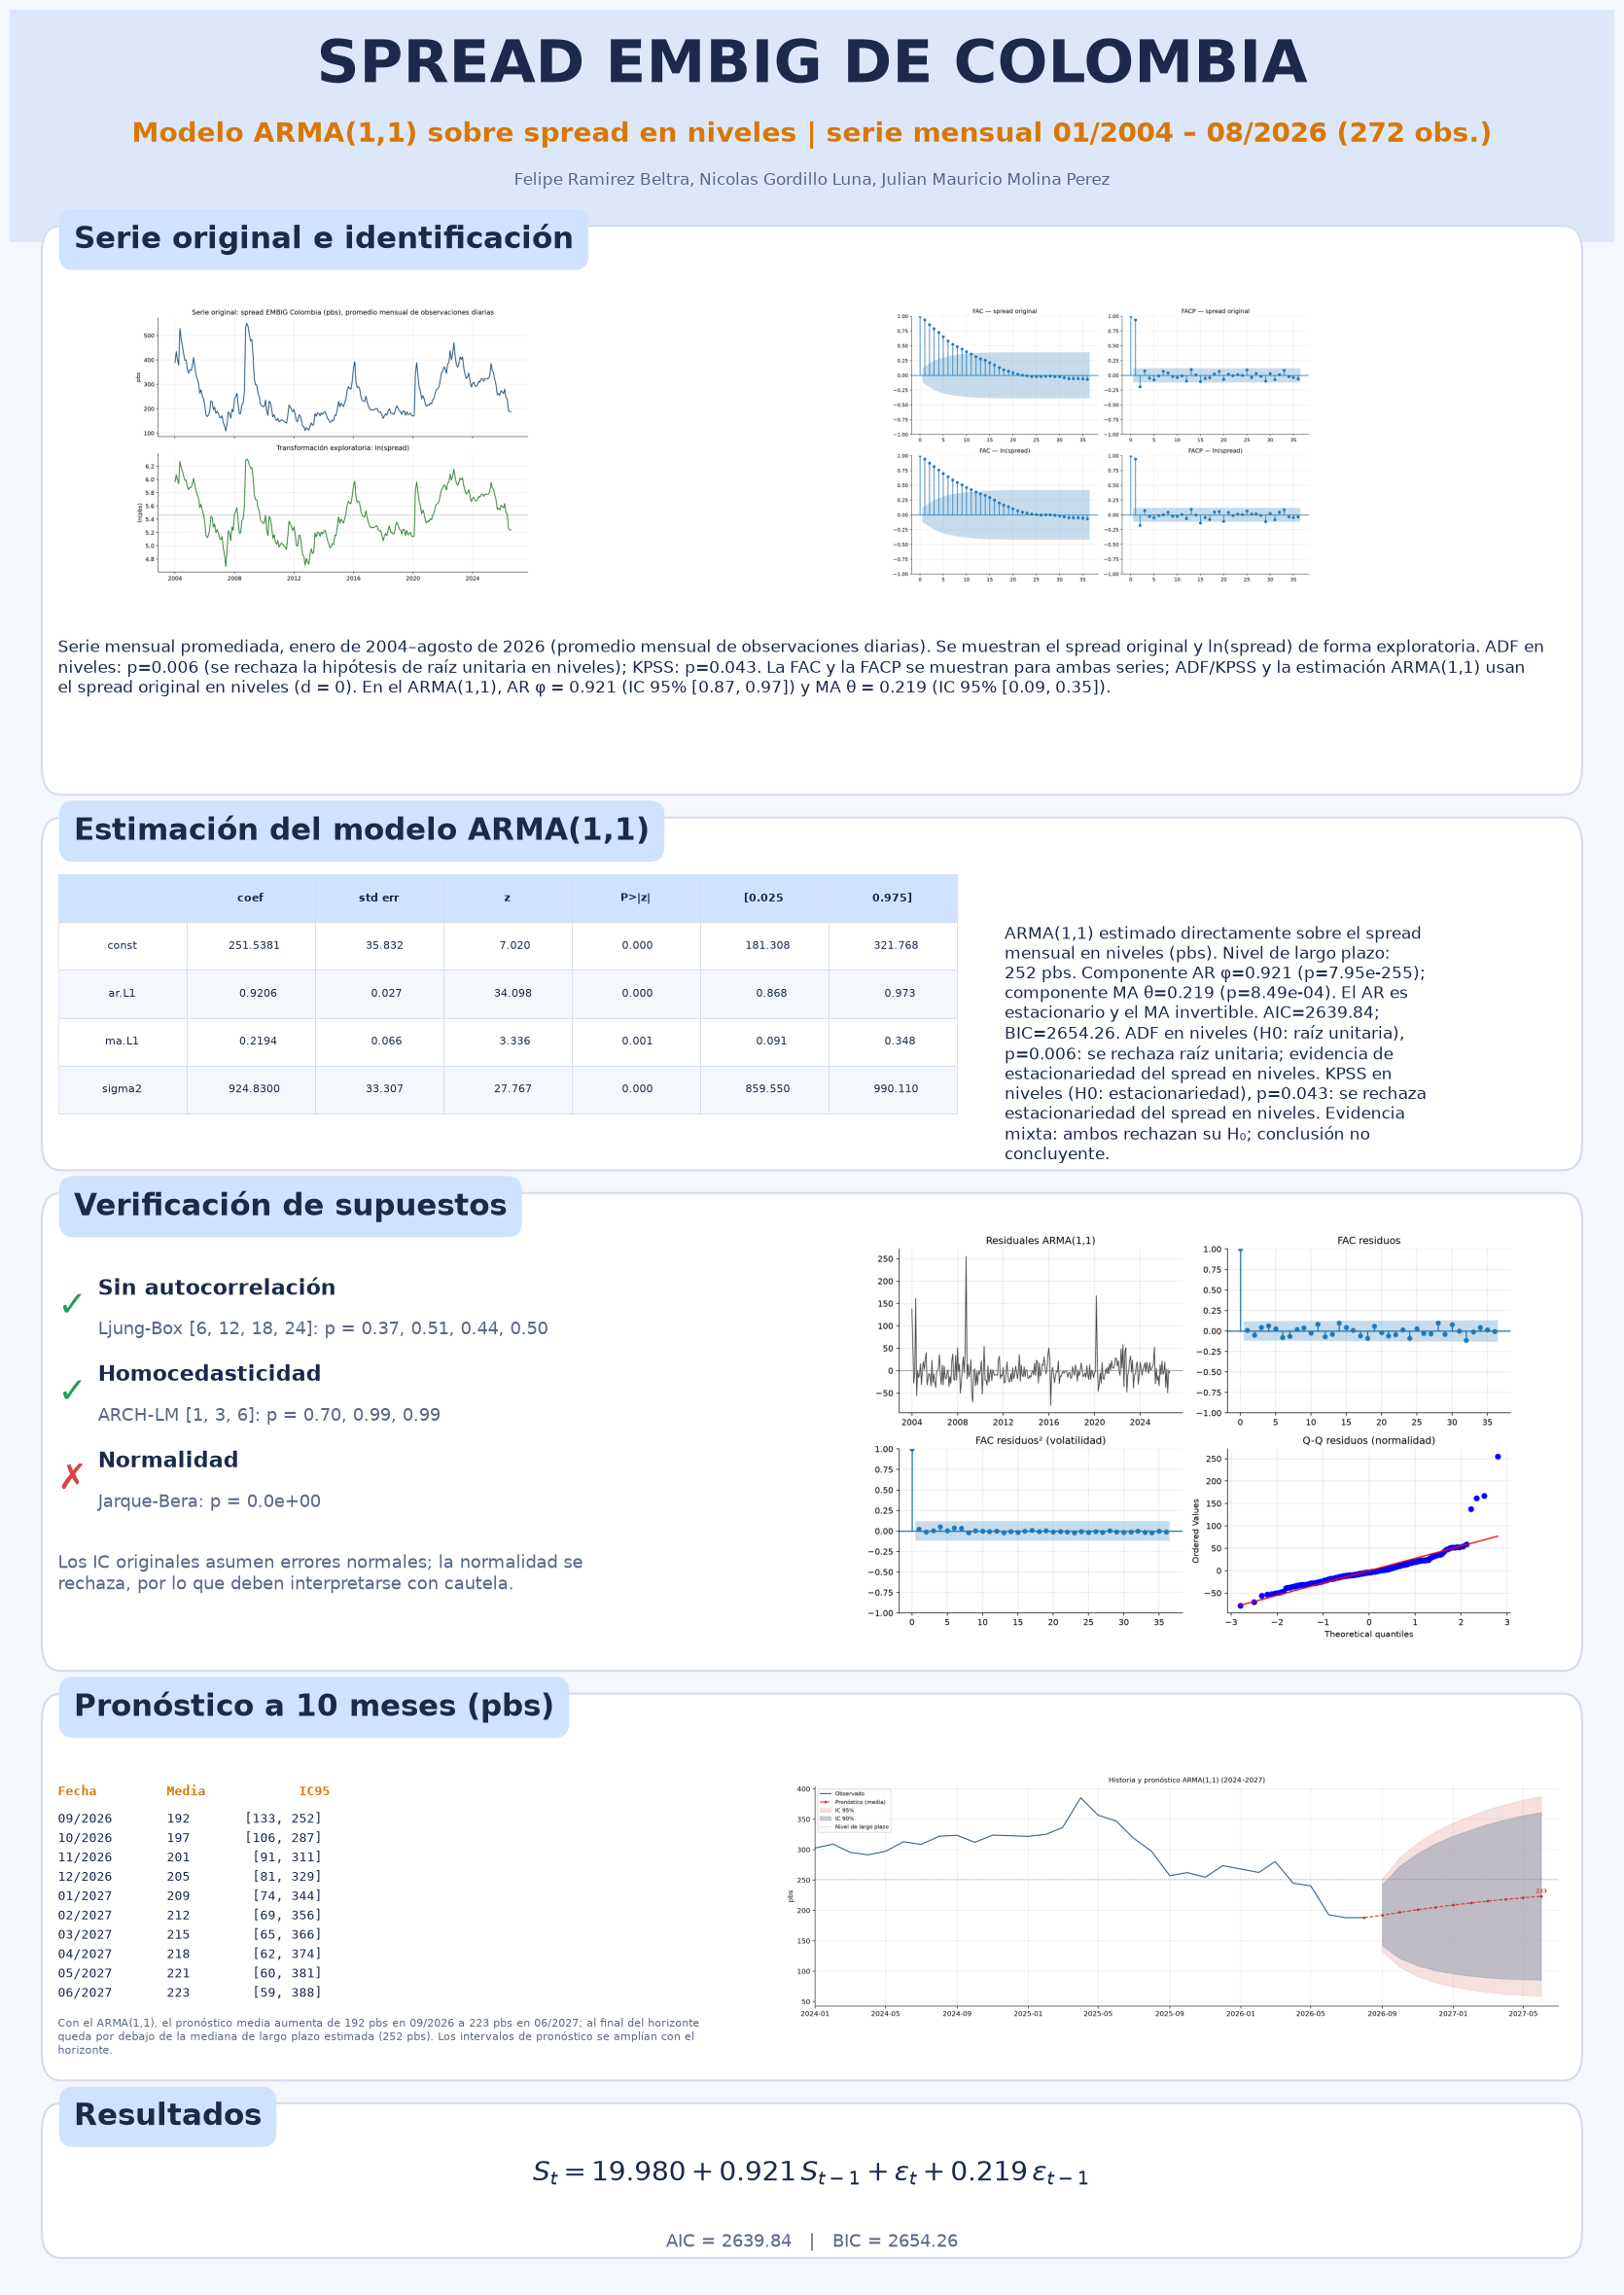

In [17]:
# Paleta clara
BG, CARD, BORDE, PILL = "#F4F7FB", "#FFFFFF", "#D5DCEB", "#CFE3FF"
INK, MUTED, ACC, OK, KO, HEAD = "#1B2A4A", "#5A6785", "#D97706", "#1E9E5A", "#D64545", "#DCE8FA"

def textos_poster(R):
    """Frases del póster, construidas con las cifras y p-valores de R (cambian solas si cambian los datos)."""
    I, M, D, P = R["ident"], R["modelo"], R["diag"], R["pron"]
    raiz = ("se rechaza la hipótesis de raíz unitaria en niveles" if I["adf_y"] < 0.05 else
            "no se rechaza la hipótesis de raíz unitaria en niveles")
    ident = (f"Serie mensual promediada, enero de 2004–agosto de 2026 ({R['agr']}). Se muestran el spread original y ln(spread) de forma exploratoria. "
             f"ADF en niveles: p={I['adf_y']:.3f} ({raiz}); KPSS: p={I['kpss_y']:.3f}. "
             f"La FAC y la FACP se muestran para ambas series; ADF/KPSS y la estimación ARMA(1,1) usan el spread original en niveles (d = 0). "
             f"En el ARMA(1,1), AR φ = {M['phi']:.3f} (IC 95% [{M['ic_phi'][0]:.2f}, {M['ic_phi'][1]:.2f}]) y MA θ = {M['theta']:.3f} (IC 95% [{M['ic_theta'][0]:.2f}, {M['ic_theta'][1]:.2f}]).")
    interp_adf = ("se rechaza raíz unitaria; evidencia de estacionariedad del spread en niveles" if I["adf_y"] < 0.05
                  else "no se rechaza raíz unitaria del spread en niveles")
    interp_kpss = ("se rechaza estacionariedad del spread en niveles" if I["kpss_y"] < 0.05
                   else "no se rechaza estacionariedad del spread en niveles")
    if I["adf_y"] < 0.05 and I["kpss_y"] < 0.05:
        acuerdo = "Evidencia mixta: ambos rechazan su H₀; conclusión no concluyente."
    elif I["adf_y"] < 0.05:
        acuerdo = "Ambos tests respaldan estacionariedad al 5%."
    elif I["kpss_y"] < 0.05:
        acuerdo = "Evidencia de no estacionariedad al 5%."
    else:
        acuerdo = "Ningún test rechaza su H₀; evidencia no concluyente."
    modelo = (f"ARMA(1,1) estimado directamente sobre el spread mensual en niveles (pbs). Nivel de largo plazo: {M['nivel_lp']:.0f} pbs. "
              f"Componente AR φ={M['phi']:.3f} (p={M['p_phi']:.2e}); componente MA θ={M['theta']:.3f} (p={M['p_theta']:.2e}). "
              f"El AR es {'estacionario' if M['phi_estacionario'] else 'no estacionario'} y el MA {'invertible' if M['theta_invertible'] else 'no invertible'}. "
              f"AIC={M['aic']:.2f}; BIC={M['bic']:.2f}. "
              f"ADF en niveles (H0: raíz unitaria), p={I['adf_y']:.3f}: {interp_adf}. "
              f"KPSS en niveles (H0: estacionariedad), p={I['kpss_y']:.3f}: {interp_kpss}. {acuerdo}")
    sup = ("Los IC originales asumen errores normales; la normalidad se rechaza, por lo que deben interpretarse con cautela."
           if D["jb_p"] < 0.05 else "Los residuos son compatibles con errores normales.")
    inicio_pron, fin_pron = P['punto'][0], P['punto'][-1]
    posicion_lp = "por debajo de" if fin_pron < M['nivel_lp'] else "por encima de"
    pron = (f"Con el ARMA(1,1), el pronóstico {P['etq']} aumenta de {inicio_pron:.0f} pbs en {P['fut'][0]:%m/%Y} "
            f"a {fin_pron:.0f} pbs en {P['fut'][-1]:%m/%Y}; al final del horizonte queda {posicion_lp} "
            f"la mediana de largo plazo estimada ({M['nivel_lp']:.0f} pbs). Los intervalos de pronóstico se amplían con el horizonte.")
    return dict(ident=ident, modelo=modelo, sup=sup, pron=pron)

def armar_poster(R, carpeta, salida_pdf, salida_png=None):
    T = textos_poster(R)
    M, D, P = R["modelo"], R["diag"], R["pron"]
    fig = plt.figure(figsize=(16.5, 23.4), facecolor=BG)
    bg = fig.add_axes([0, 0, 1, 1]); bg.set_xlim(0, 1); bg.set_ylim(0, 1); bg.axis("off")

    def card(x0, y0, w, h, titulo):
        bg.add_patch(FancyBboxPatch((x0, y0), w, h, boxstyle="round,pad=0,rounding_size=0.012", fc=CARD, ec=BORDE, lw=1.5))
        bg.text(x0 + 0.02, y0 + h - 0.006, titulo, color=INK, fontsize=22, fontweight="bold", va="center",
                bbox=dict(boxstyle="round,pad=0.5", fc=PILL, ec="none"))
    def texto(x, yv, s, w=60, size=15, color=INK, **kw):
        bg.text(x, yv, textwrap.fill(s, w), color=color, fontsize=size, va="top", ha="left", **kw)
    def imagen(rect, nombre):
        ax = fig.add_axes(rect); ax.imshow(plt.imread(carpeta / nombre)); ax.axis("off")

    # encabezado
    bg.add_patch(Rectangle((0, 0.898), 1, 0.102, fc=HEAD, ec="none"))
    bg.text(0.5, 0.975, "SPREAD EMBIG DE COLOMBIA", color=INK, fontsize=44, fontweight="bold", ha="center", va="center")
    bg.text(0.5, 0.945, f"Modelo ARMA(1,1) sobre spread en niveles | serie mensual {R['ini']} – {R['fin']} ({R['n']} obs.)",
            color=ACC, fontsize=20, ha="center", va="center", fontweight="bold")
    bg.text(0.5, 0.925, AUTORES, color=MUTED, fontsize=12, ha="center", va="center")

    # 1. serie original e identificación
    card(0.02, 0.655, 0.96, 0.250, "Serie original e identificación")
    imagen([0.03, 0.746, 0.34, 0.125], "fig1_transformacion.png")
    imagen([0.39, 0.746, 0.58, 0.125], "fig2_FAC_FACP.png")
    texto(0.03, 0.724, T["ident"], w=175, size=12)

    # 2. estimación del modelo
    card(0.02, 0.490, 0.96, 0.155, "Estimación del modelo ARMA(1,1)")
    datos_resumen = modelo.summary().tables[1].data
    ax_tabla = fig.add_axes([0.03, 0.515, 0.56, 0.105]); ax_tabla.axis("off")
    tabla = ax_tabla.table(cellText=datos_resumen[1:], colLabels=datos_resumen[0],
                           cellLoc="center", bbox=[0, 0, 1, 1])
    tabla.auto_set_font_size(False); tabla.set_fontsize(8)
    for (fila, columna), celda in tabla.get_celld().items():
        celda.set_edgecolor(BORDE); celda.set_linewidth(0.6)
        if fila == 0:
            celda.set_facecolor(PILL); celda.set_text_props(color=INK, weight="bold")
        else:
            celda.set_facecolor(CARD if fila % 2 else BG); celda.set_text_props(color=INK)
    texto(0.62, 0.598, T["modelo"], w=50, size=12)

    # 3. verificación de supuestos
    card(0.02, 0.270, 0.96, 0.210, "Verificación de supuestos")
    tests = [("Sin autocorrelación", f"Ljung-Box {LAGS_LB}: p = {', '.join(f'{v:.2f}' for v in D['lb_p'])}", D["lb_p"].min() > 0.05),
             ("Homocedasticidad", f"ARCH-LM {LAGS_ARCH}: p = {', '.join(f'{v:.2f}' for v in D['arch_p'])}", D["arch_p"].min() > 0.05),
             ("Normalidad", f"Jarque-Bera: p = {D['jb_p']:.1e}", D["jb_p"] > 0.05)]
    for i, (nom, det, ok) in enumerate(tests):
        yy = 0.430 - i * 0.038
        bg.text(0.03, yy, "✓" if ok else "✗", color=OK if ok else KO, fontsize=26, fontweight="bold", va="center")
        bg.text(0.055, yy + 0.008, nom, color=INK, fontsize=16, fontweight="bold", va="center")
        bg.text(0.055, yy - 0.010, det, color=MUTED, fontsize=13, va="center")
    texto(0.03, 0.322, T["sup"], w=62, size=13, color=MUTED)
    imagen([0.50, 0.280, 0.47, 0.185], "fig3_residuos.png")

    # 4. pronóstico completo
    card(0.02, 0.090, 0.96, 0.170, f"Pronóstico a {len(P['fut'])} meses (pbs)")
    et = P["etq"].capitalize()
    bg.text(0.03, 0.220, f"{'Fecha':10s}{et:>9s}{'IC95':>16s}", color=ACC, fontsize=9, family="monospace", va="top", fontweight="bold")
    for j, i in enumerate(range(len(P["fut"]))):
        a, b = P["ic95"][i, 0], P["ic95"][i, 1]
        bg.text(0.03, 0.208 - j * 0.0085, f"{P['fut'][i]:%m/%Y}  {P['punto'][i]:8.0f}  {f'[{a:.0f}, {b:.0f}]':>15s}",
                color=INK, fontsize=9, family="monospace", va="top")
    texto(0.03, 0.118, T["pron"], w=115, size=8, color=MUTED)
    imagen([0.48, 0.093, 0.49, 0.155], "fig4_pronostico.png")

    # 5. resultados
    card(0.02, 0.012, 0.96, 0.068, "Resultados")
    bg.text(0.5, 0.049, rf"$S_t={M['c']:.3f}+{M['phi']:.3f}\,S_{{t-1}}+\varepsilon_t+{M['theta']:.3f}\,\varepsilon_{{t-1}}$",
            color=INK, fontsize=20, ha="center", va="center")
    bg.text(0.5, 0.019, f"AIC = {M['aic']:.2f}   |   BIC = {M['bic']:.2f}",
            color=MUTED, fontsize=13, ha="center", va="center")

    fig.savefig(salida_pdf, facecolor=BG)
    if salida_png: fig.savefig(salida_png, dpi=60, facecolor=BG)
    plt.show()

armar_poster(R, SALIDA, SALIDA / "poster_embig.pdf", SALIDA / "poster_embig_preview.png")
